# Phân tích dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("diabetes_100k.csv")
data.head()

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0


In [2]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   year                  100000 non-null  int64  
 1   gender                100000 non-null  object 
 2   age                   100000 non-null  float64
 3   location              100000 non-null  object 
 4   race:AfricanAmerican  100000 non-null  int64  
 5   race:Asian            100000 non-null  int64  
 6   race:Caucasian        100000 non-null  int64  
 7   race:Hispanic         100000 non-null  int64  
 8   race:Other            100000 non-null  int64  
 9   hypertension          100000 non-null  int64  
 10  heart_disease         100000 non-null  int64  
 11  smoking_history       100000 non-null  object 
 12  bmi                   100000 non-null  float64
 13  hbA1c_level           100000 non-null  float64
 14  blood_glucose_level   100000 non-null  int64  
 15  d

In [3]:
data.describe()

,year,age,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,bmi,hbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,2018.360820,41.885856,0.202230,0.200150,0.198760,0.19888,0.199980,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,1.345239,22.516840,0.401665,0.400114,0.399069,0.39916,0.399987,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,2015.000000,0.080000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,2019.000000,24.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,2019.000000,43.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,2019.000000,60.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,2022.000000,80.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [4]:
data['diabetes'].value_counts()

diabetes
0    91500
1     8500
Name: count, dtype: int64

In [5]:
data['gender'].value_counts()

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

In [6]:
print(f"Percentage of females: {(58552/100000)*100:.2f}%")
print(f"Percentage of males: {(41430/100000)*100:.2f}%")
print(f"Percentage of other: {(18/100000)*100:.2f}%")

Percentage of females: 58.55%
Percentage of males: 41.43%
Percentage of other: 0.02%


In [7]:
data[['race:AfricanAmerican', 'race:Asian', 'race:Caucasian', 'race:Hispanic', 'race:Other']].sum()

race:AfricanAmerican    20223
race:Asian              20015
race:Caucasian          19876
race:Hispanic           19888
race:Other              19998
dtype: int64

# Biểu đồ

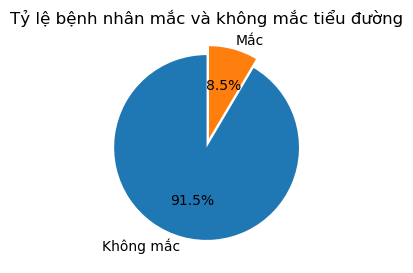

In [8]:
import matplotlib.pyplot as plt

counts = data["diabetes"].value_counts()

plt.figure(figsize=(3, 3))
plt.pie(
    counts,
    labels=["Không mắc", "Mắc"],
    autopct="%1.1f%%",
    startangle=90,
    explode=[0, 0.1]
)

plt.title("Tỷ lệ bệnh nhân mắc và không mắc tiểu đường")
plt.show()

<Axes: xlabel='gender', ylabel='count'>

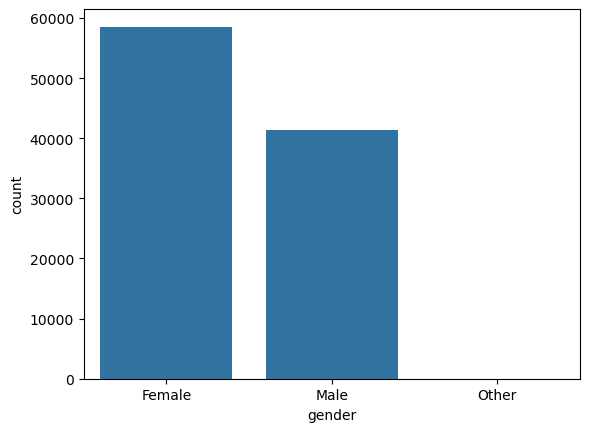

In [9]:
sns.countplot(data=data, x='gender', order=data['gender'].value_counts().index)

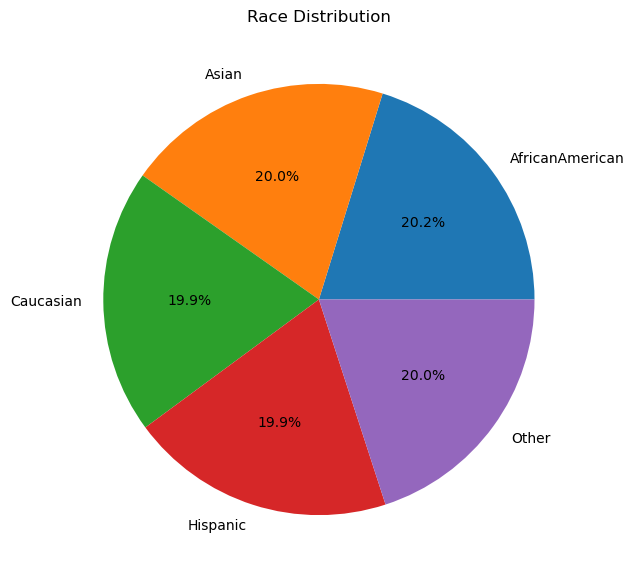

In [10]:
race_data = data.loc[:, data.columns.str.contains('race')]

race_counts = race_data.sum()
race_counts.index = race_counts.index.str.replace('race:', '', regex=False)

race_counts.plot.pie(
    autopct='%1.1f%%',
    figsize=(7, 7)
)

plt.ylabel('')
plt.title('Race Distribution')
plt.show()

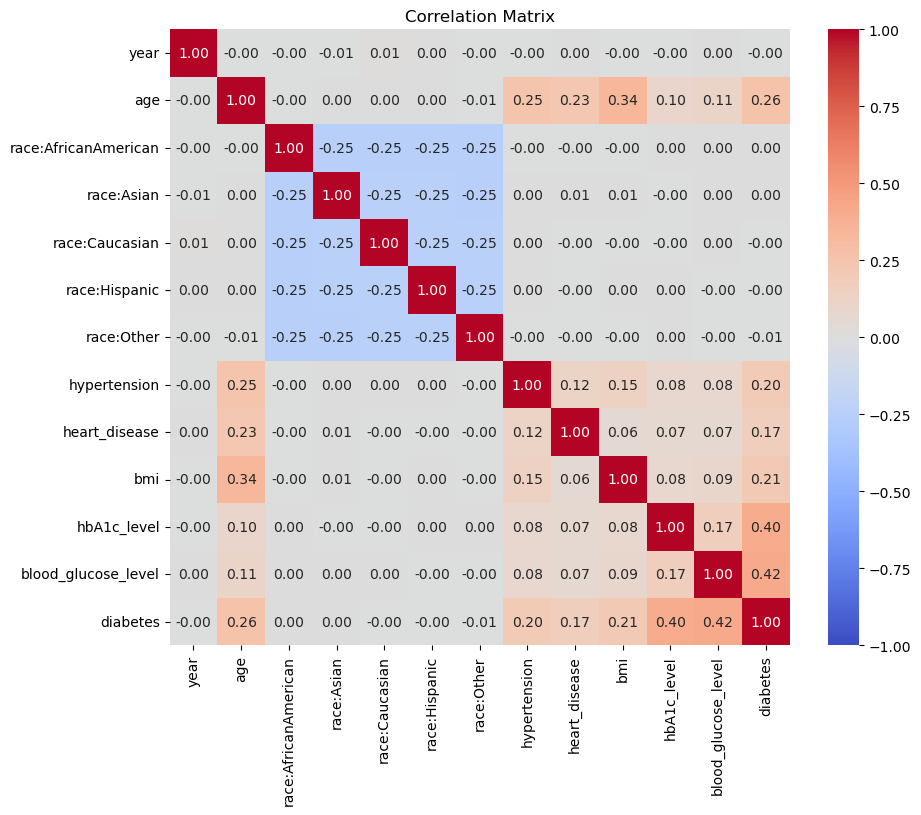

In [11]:
# Correlation between features
corr = data.select_dtypes(include='number').corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.show()

# Tiền xử lý dữ liệu

In [12]:
# Check for null/empty cells
data.isnull().sum()

year                    0
gender                  0
age                     0
location                0
race:AfricanAmerican    0
race:Asian              0
race:Caucasian          0
race:Hispanic           0
race:Other              0
hypertension            0
heart_disease           0
smoking_history         0
bmi                     0
hbA1c_level             0
blood_glucose_level     0
diabetes                0
dtype: int64

In [13]:
data = pd.get_dummies(
    data,
    columns=['gender', 'smoking_history'],
    dtype=int
)

data = data.drop(columns=['year', 'location'])

In [43]:
X = data.loc[:, data.columns != 'diabetes'] # Input features
y = data['diabetes'] # Output labels

feature_names = X.columns.tolist()

In [15]:
from sklearn.model_selection import train_test_split

# Split dataset into 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=.2, stratify = y,
        random_state=42, shuffle = True
    )

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((80000, 20), (20000, 20), (80000,), (20000,))

In [16]:
# Scale Features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Mô hình

In [17]:
from sklearn.model_selection import cross_val_score

# So sánh hyperparameters
def drawCrossChart(range_list, model_func, xlabel, title):
    scores = []
    for r in range_list:
        model = model_func(r)
        s = cross_val_score(
            model,
            X_train,
            y_train,
            scoring='accuracy',
            cv=5
        )
        scores.append(np.mean(s))

    import matplotlib.pyplot as plt
    plt.style.use("ggplot")
    plt.plot(range_list, scores, marker='*', color='r')
    plt.xlabel(xlabel)
    plt.ylabel("Accuracy")
    plt.title(title)

    plt.show()

In [18]:
from sklearn import metrics

# Function for evaluating model's performance on test dataset
def evaluation(y_test, y_pred):
    print(f"Model Accuracy: {metrics.accuracy_score(y_test, y_pred)*100:.2f}%")
    print(f"Classification Report:\n {metrics.classification_report(y_test, y_pred)}")
    cm = metrics.confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot = True, fmt = ".2f",
        xticklabels = ['Negative','Positive'],
        yticklabels = ['Negative','Positive']
    )
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted Label", fontsize = 15)
    plt.ylabel("Actual Label", fontsize = 15)

## 1. Logistic Regression

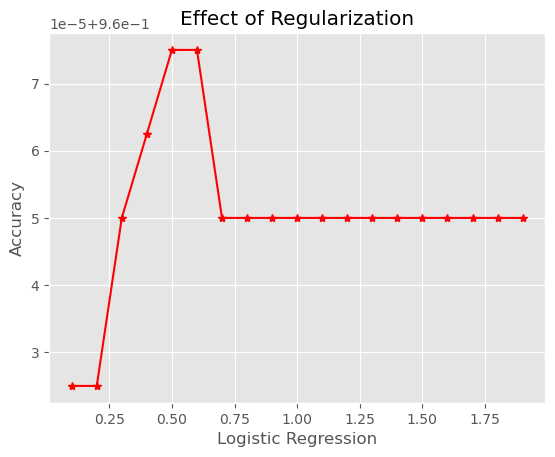

In [19]:
from sklearn.linear_model import LogisticRegression

rgl_values = np.arange(0.1, 2, 0.1)
drawCrossChart(
    range_list = rgl_values,
    model_func=lambda r: LogisticRegression(C=r),
    xlabel="Logistic Regression",
    title="Effect of Regularization"
)

Model Accuracy: 96.06%
Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.99      0.98     18300
           1       0.87      0.63      0.73      1700

    accuracy                           0.96     20000
   macro avg       0.92      0.81      0.86     20000
weighted avg       0.96      0.96      0.96     20000



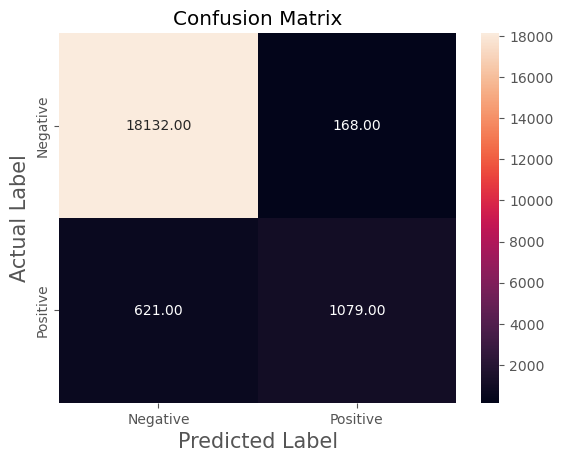

In [20]:
logr = LogisticRegression(C=0.5)
logr.fit(X_train, y_train)
logr_pred = logr.predict(X_test)
evaluation(y_test, logr_pred)

## 2. KNN

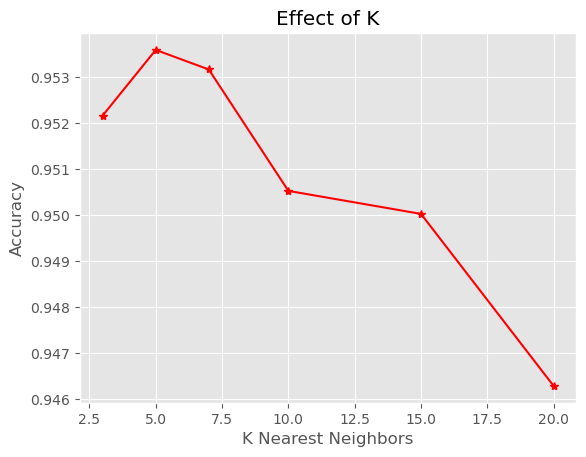

In [21]:
from sklearn.neighbors import KNeighborsClassifier

k_values = [3, 5, 7, 10, 15, 20]
drawCrossChart(
    range_list = k_values,
    model_func=lambda r: KNeighborsClassifier(n_neighbors=r),
    xlabel="K Nearest Neighbors",
    title="Effect of K"
)

Model Accuracy: 95.64%
Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.99      0.98     18300
           1       0.88      0.56      0.69      1700

    accuracy                           0.96     20000
   macro avg       0.92      0.78      0.83     20000
weighted avg       0.95      0.96      0.95     20000



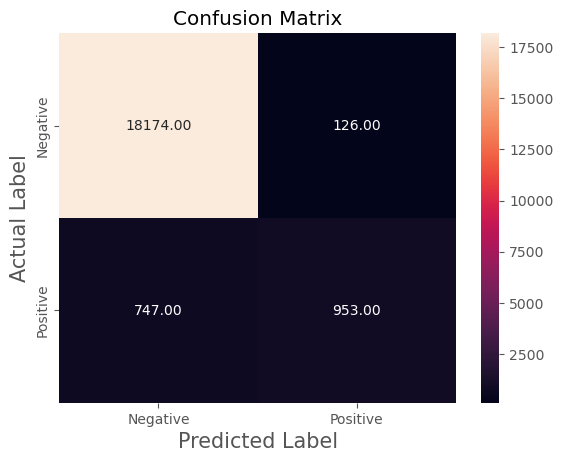

In [22]:
knn = KNeighborsClassifier(n_neighbors = 5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)
evaluation(y_test, knn_pred)

## 3. Decision Tree

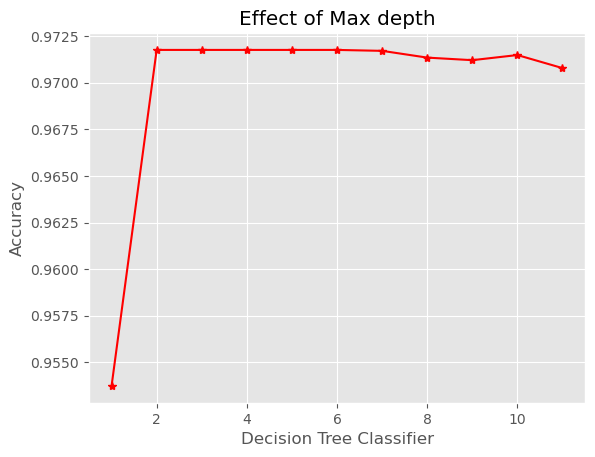

In [23]:
from sklearn.tree import DecisionTreeClassifier

d_values = list(range(1, 12))
drawCrossChart(
    range_list = d_values,
    model_func=lambda r: DecisionTreeClassifier(max_depth=r),
    xlabel="Decision Tree Classifier",
    title="Effect of Max depth"
)


Model Accuracy: 97.23%
Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.99     18300
           1       1.00      0.67      0.81      1700

    accuracy                           0.97     20000
   macro avg       0.99      0.84      0.90     20000
weighted avg       0.97      0.97      0.97     20000



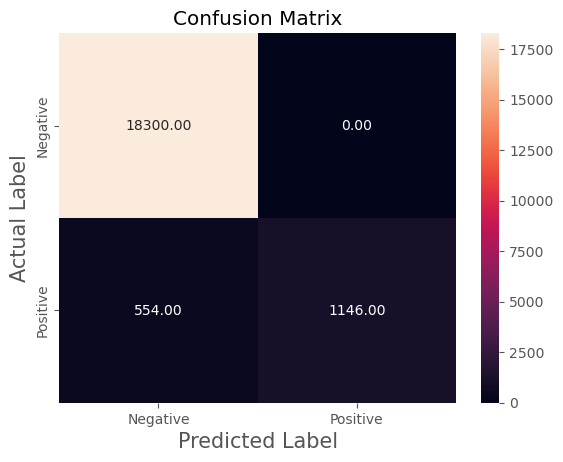

In [24]:
dt = DecisionTreeClassifier(max_depth=2)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
evaluation(y_test, dt_pred)

## 4.Random Forest Classifier

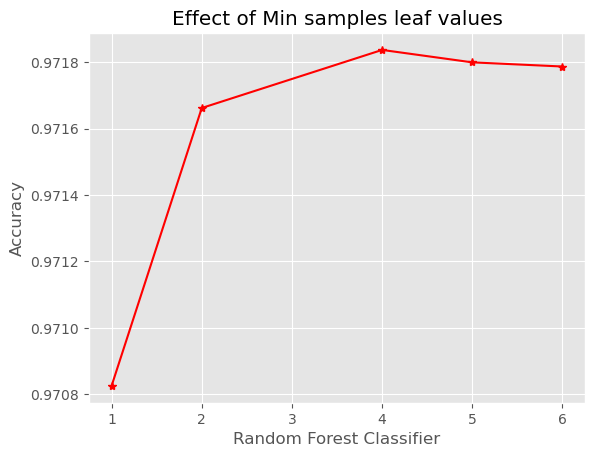

In [25]:
from sklearn.ensemble import RandomForestClassifier

min_leaf_values = [1, 2, 4, 5, 6]
drawCrossChart(
    range_list = min_leaf_values,
    model_func=lambda r: RandomForestClassifier(min_samples_leaf=r, n_jobs=-1),
    xlabel="Random Forest Classifier",
    title="Effect of Min samples leaf values"
)


Model Accuracy: 97.24%
Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.99     18300
           1       1.00      0.68      0.81      1700

    accuracy                           0.97     20000
   macro avg       0.98      0.84      0.90     20000
weighted avg       0.97      0.97      0.97     20000



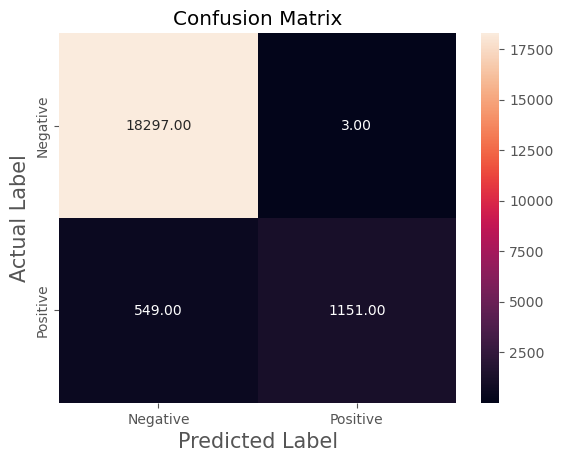

In [26]:
rf = RandomForestClassifier(min_samples_leaf=4)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
evaluation(y_test, rf_pred)

## 5. SVC

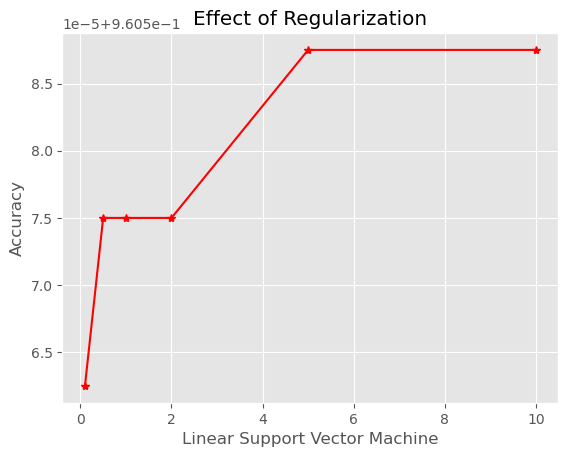

In [33]:
from sklearn.svm import LinearSVC

rgl_values = [0.1, 0.5, 1, 2, 5, 10]

drawCrossChart(
    range_list=rgl_values,
    model_func=lambda r: LinearSVC(C=r, max_iter=5000),
    xlabel="Linear Support Vector Machine",
    title="Effect of Regularization"
)

Model Accuracy: 96.16%
Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.99      0.98     18300
           1       0.90      0.62      0.73      1700

    accuracy                           0.96     20000
   macro avg       0.93      0.80      0.86     20000
weighted avg       0.96      0.96      0.96     20000



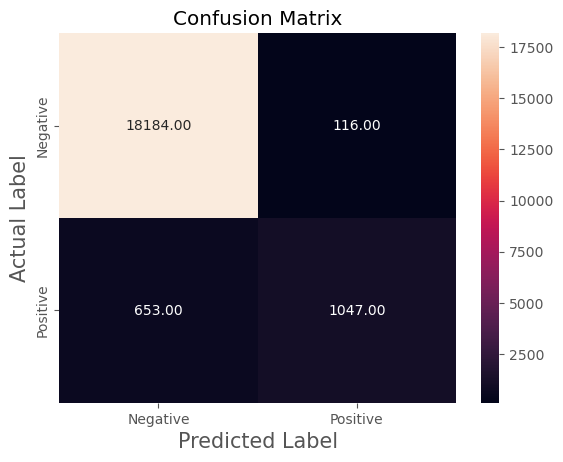

In [32]:
svm = LinearSVC(C=5, max_iter=5000)
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)
evaluation(y_test, svm_pred)

# So sánh model

In [34]:
#baseline
from sklearn.dummy import DummyClassifier
baseline = DummyClassifier(strategy ="most_frequent")
baseline.fit(X_train , y_train)

,strategy,'most_frequent'
,random_state,None
,constant,None


In [35]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    confusion_matrix
)

results = []

for model in [baseline, logr, knn, dt, rf, svm]:
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    pc = precision_score(y_test, y_pred)
    rc = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    results.append([acc, pc, rc, f1, cm])

algorithms = [
    "Baseline", "Logistic Regression",
    "K-Nearest Neighbors", "Decision Tree",
    "Random Forest Classifier", "LinearSVC"
]
res_df = pd.DataFrame(results,index = algorithms)
res_df.columns=[
    "Accuracy", "Precision",
    "Recall", "F1-score", "Confusion Matrix"
]
res_df.sort_values(by="Accuracy",ascending=False)


d:\Program Files\Anaconda\envs\notebook-env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Accuracy,Precision,Recall,F1-score,Confusion Matrix
Random Forest Classifier,0.97240,0.997400,0.677059,0.806587,"[[18297, 3], [549, 1151]]"
Decision Tree,0.97230,1.000000,0.674118,0.805341,"[[18300, 0], [554, 1146]]"
LinearSVC,0.96155,0.900258,0.615882,0.731401,"[[18184, 116], [653, 1047]]"
Logistic Regression,0.96055,0.865277,0.634706,0.732270,"[[18132, 168], [621, 1079]]"
K-Nearest Neighbors,0.95635,0.883225,0.560588,0.685858,"[[18174, 126], [747, 953]]"
Baseline,0.91500,0.000000,0.000000,0.000000,"[[18300, 0], [1700, 0]]"


# Triển khai

In [40]:
# Tính giá trị trung bình của các feature dạng số
non_diabetic = data[data["diabetes"] == 0]
reference_means = non_diabetic[['age', 'bmi', 'hbA1c_level', 'blood_glucose_level']].mean()

print(reference_means)

age                     40.115187
bmi                     26.887163
hbA1c_level              5.396761
blood_glucose_level    132.852470
dtype: float64


In [44]:
import joblib

joblib.dump(
    {
        "model": rf,
        "scaler": scaler,
        "feature_names": feature_names,
        "reference_means": reference_means
    },
    "rf_diabetes.pkl"
)

['rf_diabetes.pkl']

In [ ]:
import joblib

joblib.dump(
    {
        "": rf,
        "scaler": scaler,
        "feature_names": feature_names,
        "reference_means": reference_means
    },
    "rf_diabetes.pkl"
)